In [ ]:
#Step 1: Install Necessary Libraries
!pip install -q kaggle torch torchvision torch_xla

In [ ]:
#2. Setting Up the Kaggle API
import os
from google.colab import files
!mkdir -p ~/.kaggle
files.upload() # Upload kaggle.json manually
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
#3. Download and Extract the Dataset
import kaggle
kaggle.api.dataset_download_files('paultimothymooney/chest-xray-pneumonia', path='./', unzip=True)


Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia


In [ ]:
#4. Import Required Libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
import torch_xla.core.xla_model as xm
import torch_xla.distributed.parallel_loader as pl
import numpy as np
import cv2
import matplotlib.pyplot as plt

/usr/local/lib/python3.11/dist-packages/torch_xla/__init__.py:253: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(


In [ ]:
#5. Defining the Custom Dataset Class
class ChestXRayDataset(Dataset):
    def __init__(self, root_dir):
        self.images = []
        self.labels = []
        categories = ["NORMAL", "PNEUMONIA"]
        for label, category in enumerate(categories):
            path = os.path.join(root_dir, category)
            for file in os.listdir(path):
                self.images.append(os.path.join(path, file))
                self.labels.append(label)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = cv2.imread(self.images[idx], cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (224, 224))
        image = np.stack([image] * 3, axis=-1)  # Convert grayscale to 3-channel
        image = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1) / 255.0  # Normalize
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

In [ ]:
#6. Load Training and Test Datasets
train_dir = "./chest_xray/train"
test_dir = "./chest_xray/test"
train_dataset = ChestXRayDataset(train_dir)
test_dataset = ChestXRayDataset(test_dir)

In [ ]:
#7. Create TPU-Optimized DataLoaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
#8. Visualizing Sample Images
def show_sample_images(dataset, num_images=10):
    fig, axes = plt.subplots(2, num_images // 2, figsize=(15, 6))
    for i in range(num_images):
        image, label = dataset[i]
        image = image.permute(1, 2, 0).numpy()
        axes[i // (num_images//2), i % (num_images//2)].imshow(image, cmap="gray")
        axes[i // (num_images//2), i % (num_images//2)].set_title("Normal" if label == 0 else "Pneumonia")
        axes[i // (num_images//2), i % (num_images//2)].axis("off")
    plt.suptitle("Random Sample Images from Dataset")
    plt.show()

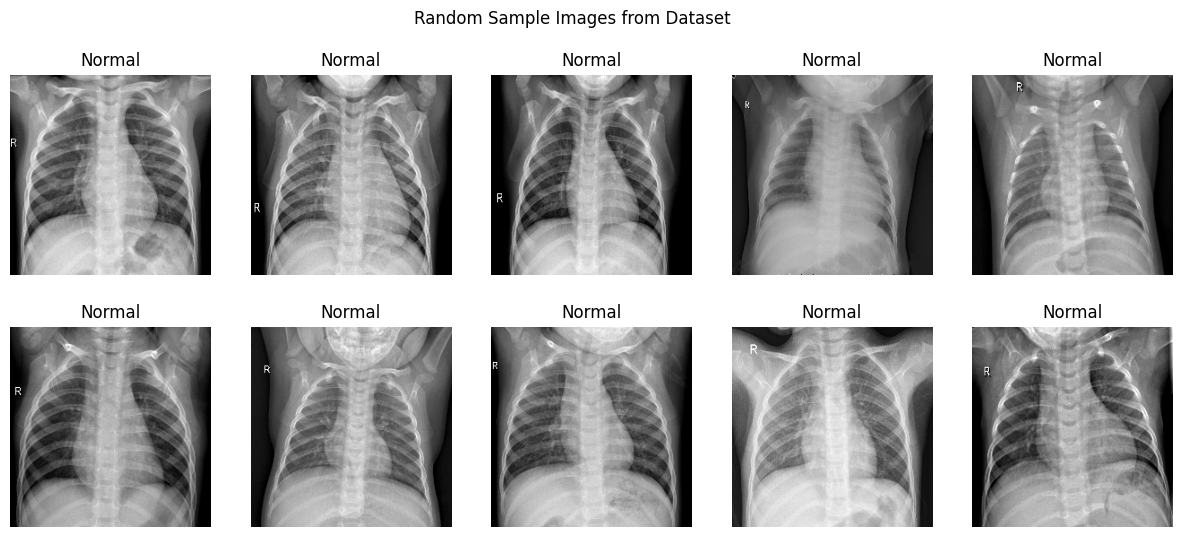

In [ ]:
# Show sample training images
show_sample_images(train_dataset, num_images=10)

# Function to evaluate the model using pneumonia images only
def evaluate_pneumonia_only(model, test_loader, device, num_images=10):
    model.eval()
    correct = 0
    total = 0
    predictions = []
    images_list = []
    labels_list = []

    with torch.no_grad():
        para_loader = pl.ParallelLoader(test_loader, [device]).per_device_loader(device)
        for images, labels in para_loader:
            images, labels = images.to(device), labels.to(device)

            # Mask to select only pneumonia images
            mask = labels == 1
            images = images[mask]
            labels = labels[mask]

            if len(images) == 0:
                continue  # Skip if no pneumonia images in this batch

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            # Store images & predictions for visualization
            images_list.extend(images.cpu().numpy())
            labels_list.extend(labels.cpu().numpy())
            predictions.extend(predicted.cpu().numpy())

            if len(predictions) >= num_images:
                break

    # Calculate accuracy on pneumonia images
    accuracy = 100 * correct / total
    print(f'Test Accuracy (Pneumonia only): {accuracy:.2f}%')

    # Show predictions on pneumonia test samples
    fig, axes = plt.subplots(2, num_images // 2, figsize=(15, 6))
    for i in range(num_images):
        image = images_list[i].transpose(1, 2, 0)
        axes[i // (num_images//2), i % (num_images//2)].imshow(image, cmap="gray")
        label = "Pneumonia" if labels_list[i] == 1 else "Normal"
        pred = "Pneumonia" if predictions[i] == 1 else "Normal"
        color = "green" if label == pred else "red"
        axes[i // (num_images//2), i % (num_images//2)].set_title(f"Actual: {label}\nPred: {pred}", color=color)
        axes[i // (num_images//2), i % (num_images//2)].axis("off")
    plt.suptitle("Pneumonia Test Sample Predictions")
    plt.show()


In [ ]:
# Model evaluation for both NORMAL and PNEUMONIA test samples with image visualization
def evaluate_model_with_visualization(model, test_loader, device, num_samples=5):
    model.eval()
    correct = 0
    total = 0
    pneumonia_correct = 0
    pneumonia_total = 0
    normal_correct = 0
    normal_total = 0
    images_shown = 0

    # Create figure for visualizing images
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            # Track accuracy for PNEUMONIA class
            pneumonia_indices = (labels == 1)
            pneumonia_correct += (predicted[pneumonia_indices] == labels[pneumonia_indices]).sum().item()
            pneumonia_total += pneumonia_indices.sum().item()

            # Track accuracy for NORMAL class
            normal_indices = (labels == 0)
            normal_correct += (predicted[normal_indices] == labels[normal_indices]).sum().item()
            normal_total += normal_indices.sum().item()

            # Show images for evaluation
            for i in range(images.size(0)):
                if images_shown >= num_samples:
                    break

                image = images[i].cpu().numpy().transpose(1, 2, 0)  # Convert to HWC format
                image = np.clip(image, 0, 1)  # Normalize image

                ax = axes[images_shown]
                ax.imshow(image)

                # Get the label and prediction (NORMAL or PNEUMONIA)
                true_label = 'NORMAL' if labels[i].item() == 0 else 'PNEUMONIA'
                pred_label = 'NORMAL' if predicted[i].item() == 0 else 'PNEUMONIA'
                ax.set_title(f'Truth: {true_label}\nPred: {pred_label}')
                ax.axis('off')

                images_shown += 1

    # Calculate accuracy
    accuracy = 100 * correct / total
    pneumonia_accuracy = 100 * pneumonia_correct / pneumonia_total if pneumonia_total > 0 else 0
    normal_accuracy = 100 * normal_correct / normal_total if normal_total > 0 else 0

    print(f"Total Accuracy: {accuracy:.2f}%")
    print(f"PNEUMONIA Accuracy: {pneumonia_accuracy:.2f}%")
    print(f"NORMAL Accuracy: {normal_accuracy:.2f}%")

    plt.show()

Epoch 1, Loss: 0.1153, Accuracy: 95.94%
Epoch 2, Loss: 0.0287, Accuracy: 98.89%
Epoch 3, Loss: 0.0321, Accuracy: 98.83%
Epoch 4, Loss: 0.0198, Accuracy: 99.31%
Epoch 5, Loss: 0.0204, Accuracy: 99.19%
Total Accuracy: 79.97%
PNEUMONIA Accuracy: 97.18%
NORMAL Accuracy: 51.28%


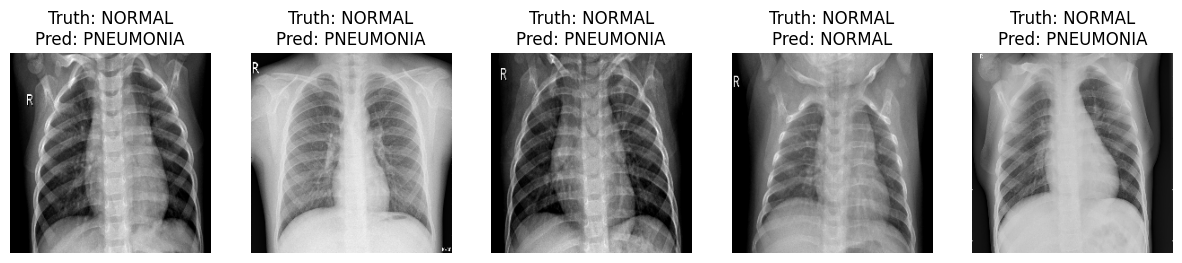

Test Accuracy (Pneumonia only): 90.91%


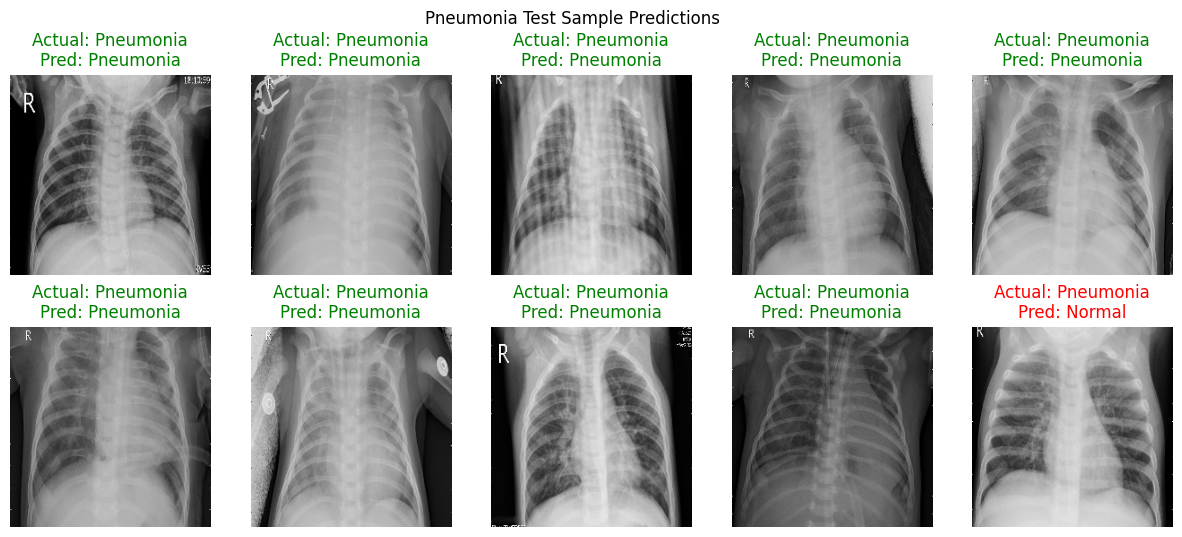

In [ ]:

# Define training function for TPU
def train_model(model, optimizer, criterion, train_loader, device, num_epochs=7):
    model.train()
    loss_history = []
    accuracy_history = []

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        para_loader = pl.ParallelLoader(train_loader, [device]).per_device_loader(device)
        for images, labels in para_loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            xm.optimizer_step(optimizer)

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)
        xm.master_print(f'Epoch {epoch+1}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%')

    return loss_history, accuracy_history

# Initialize model and optimizer
device = xm.xla_device()  # Ensure TPU device is used
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)  # 2 classes: Normal & Pneumonia
model = model.to(device)

# Train model (training function defined earlier)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
train_model(model, optimizer, criterion, train_loader, device, num_epochs=5)

# Evaluate model
evaluate_model_with_visualization(model, test_loader, device, num_samples=5)

# Evaluate pneumonia images specifically
evaluate_pneumonia_only(model, test_loader, device, num_images=10)